<img src="images/utfsm.png" alt="" width="150px" align="left"/>
<img src="images/utfsm.png" alt="" width="150px" align="right"/>
<br/>
<div align="center">
<h2>IPD-434 Seminario de Soft Computing</h2><br/>
<h1>Certamen - 2026</h1>
<br/><br/>
Dr. Patricio Olivares Roncagliolo<br/><br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María
</div>

- **Alumno**: Francisco Alfaro Medina
- **Rol**: 201110007-7


# Pregunta Lógica Difusa

## Contexto

Usted trabaja para una destacada empresa tecnológica especializada en el desarrollo de sistemas inteligentes para una amplia variedad de electrodomésticos, que incluyen refrigeradores, lavadoras, hornos microondas y aspiradoras, entre otros. Su objetivo es diseñar un sistema de control inteligente que hará uso de la lógica difusa para garantizar un funcionamiento intuitivo y eficiente, considerando las distintas condiciones de uso y las preferencias del usuario.


Para una mejor comprensión del problema, se le presentan tres artículos de divulgación científica que describen sistemas de control inteligente basados en lógica difusa para electrodomésticos. Usted puede basarse en estos artículos para resolver la pregunta o bien utilizarlos como referencia para la búsqueda de un artículo científico que le permita resolver la pregunta.

1. [**Implementation of fuzzy control in a domestic refrigerator considering the influence of the thermal load**](https://doi.org/10.1016/j.ijrefrig.2022.12.018)

2. [**Washing machine using fuzzy logic controller to provide wash quality**](https://doi.org/10.1007/s00500-020-05477-4)

3. [**Rule base reduction for knowledge-based fuzzy controllers with application to a vacuum cleaner**](https://doi.org/10.1016/j.eswa.2004.10.009)

## Objetivo

Su misión consiste en lo siguiente:


### 1. **Especificación del Electrodoméstico y Contexto**

Seleccione el tipo de electrodoméstico en el que se enfocará para la implementación de este sistema de control inteligente. Puede elegir entre refrigeradores, lavadoras, hornos microondas, aspiradoras u otro de su interés. Su elección debe estar respaldada por un trabajo de investigación científica que le servirá de base para responder esta pregunta. Describa el contexto específico en el que operará este electrodoméstico. Por ejemplo, si opta por una lavadora inteligente, podría situarla en un hogar con grandes volúmenes de ropa y diferentes tipos de tejidos.


**Lavadora inteligente** con un controlador de lógica difusa que decide, de forma automática, el programa de lavado (tiempo, temperatura y velocidad de centrifugado) a partir de las características de la carga.

**Contexto de operación**

El sistema operará en un **hogar familiar con grandes volúmenes de ropa y distintos tipos de tejidos** (seda, lana y algodón), donde cada carga varía en peso y en nivel de suciedad. En este escenario el usuario no sabe con precisión cuánto tiempo ni qué temperatura necesita cada carga, y un programa fijo tiende a desperdiciar agua, energía y tiempo en cargas livianas o poco sucias, o a lavar de forma insuficiente las muy sucias. Además, la relación entre cantidad de ropa, suciedad y tiempo de lavado no es una fórmula exacta, por lo que las reglas expresadas en términos lingüísticos ("poca carga", "muy sucia") son una forma natural de modelarla.

**Respaldo científico**
**Artículo base:** Raja, K. y Ramathilagam, S. (2021). *Washing machine using fuzzy logic controller to provide wash quality*. Soft Computing, 25, 9957–9965. https://doi.org/10.1007/s00500-020-05477-4

- Propone un controlador difuso tipo Mamdani con tres entradas (tipo de tela, grado de suciedad y masa de la carga) y salidas como tiempo de lavado, temperatura, RPM y tiempo de secado.
- Define 27 reglas SI-ENTONCES y usa defuzzificación por centroide.
- Su motivación es ahorrar agua, energía y tiempo mediante un lavado ajustado a cada carga.

> **Nota**: Para la implementación en Python con `scikit-fuzzy` se tomaron como referencia técnica algunos repositorios públicos de GitHub. No constituyen respaldo científico; solo sirvieron de guía para la estructura del código.
> - https://github.com/TEL-USM/IPD434/tree/2026-2
> - https://github.com/Sookchand/Fuzzy-Logic-Washing-Machine
> - https://github.com/Guoxuan99/Washing-Machine-Fuzzy-Logic-Controller

### 2. **Diseño e Implementación del Sistema**

Diseñe e implemente un sistema de lógica difusa que contemple al menos dos entradas y al menos dos salidas. Asegúrese de adaptar el sistema para que funcione de manera eficiente, considerando las variables cambiantes del uso o entorno del electrodoméstico, así como las preferencias del usuario.

Se implementa un controlador difuso tipo **Mamdani** basado en Raja y Ramathilagam (2021), con **3 entradas** y **3 salidas**, usando `scikit-fuzzy`.

| Tipo | Variable | Universo | Conjuntos difusos |
|---|---|---|---|
| Entrada | Tipo de tela | 0–10 (delicada → resistente) | seda, lana, algodón |
| Entrada | Nivel de suciedad | 0–100 | no grasosa, media, grasosa |
| Entrada | Carga de ropa | 0–20 kg | baja (<10), media (10–15), alta (>15) |
| Salida | Tiempo de lavado | 0–60 min | muy corto, corto, medio, largo, muy largo |
| Salida | Temperatura | 10–70 °C | fría, tibia, caliente |
| Salida | Velocidad de centrifugado | 400–1400 rpm | baja, media, alta |

**Adaptaciones respecto del artículo**
- El artículo no entrega los parámetros de las funciones de pertenencia (solo figuras), por lo que se definieron funciones triangulares y trapezoidales propias.
- El tipo de tela es categórico en el artículo; aquí se modela como una escala numérica de delicadeza para mantenerlo como variable difusa.
- Las etiquetas de RPM del artículo (Quick, Intermediate, Long) se interpretaron como baja, media y alta.
- De las 5 salidas del artículo se implementan 3 (tiempo, temperatura y RPM).
- Base de reglas: las 27 reglas del artículo, generadas desde una tabla.

In [1]:
!pip3 install scikit-fuzzy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


In [2]:
# variables y funciones de pertenencia

import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# Entradas
tela     = ctrl.Antecedent(np.arange(0, 10.01, 0.1), 'tela')
suciedad = ctrl.Antecedent(np.arange(0, 100.1, 1),   'suciedad')
carga    = ctrl.Antecedent(np.arange(0, 20.01, 0.1), 'carga')

# Salidas
tiempo      = ctrl.Consequent(np.arange(0, 60.1, 0.5),     'tiempo')
temperatura = ctrl.Consequent(np.arange(10, 70.1, 0.5),    'temperatura')
rpm         = ctrl.Consequent(np.arange(400, 1400.1, 5),   'rpm')

# Funciones de pertenencia: entradas
tela['seda']    = fuzz.trimf(tela.universe, [0, 0, 5])
tela['lana']    = fuzz.trimf(tela.universe, [0, 5, 10])
tela['algodon'] = fuzz.trimf(tela.universe, [5, 10, 10])

suciedad['no_grasosa'] = fuzz.trimf(suciedad.universe, [0, 0, 50])
suciedad['media']      = fuzz.trimf(suciedad.universe, [0, 50, 100])
suciedad['grasosa']    = fuzz.trimf(suciedad.universe, [50, 100, 100])

carga['baja']  = fuzz.trapmf(carga.universe, [0, 0, 6, 10])
carga['media'] = fuzz.trimf(carga.universe,  [7, 12.5, 18])
carga['alta']  = fuzz.trapmf(carga.universe, [14, 17, 20, 20])

# Funciones de pertenencia: salidas
tiempo['muy_corto'] = fuzz.trimf(tiempo.universe, [0, 0, 15])
tiempo['corto']     = fuzz.trimf(tiempo.universe, [0, 15, 30])
tiempo['medio']     = fuzz.trimf(tiempo.universe, [15, 30, 45])
tiempo['largo']     = fuzz.trimf(tiempo.universe, [30, 45, 60])
tiempo['muy_largo'] = fuzz.trimf(tiempo.universe, [45, 60, 60])

temperatura['fria']     = fuzz.trimf(temperatura.universe, [10, 10, 40])
temperatura['tibia']    = fuzz.trimf(temperatura.universe, [10, 40, 70])
temperatura['caliente'] = fuzz.trimf(temperatura.universe, [40, 70, 70])

rpm['baja']  = fuzz.trimf(rpm.universe, [400, 400, 900])
rpm['media'] = fuzz.trimf(rpm.universe, [400, 900, 1400])
rpm['alta']  = fuzz.trimf(rpm.universe, [900, 1400, 1400])

/Users/franciscoalfaro/Documents/00_fralfaro/IPD434/.venv/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


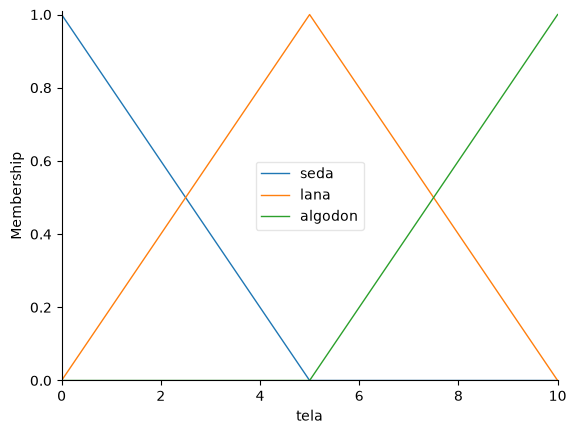

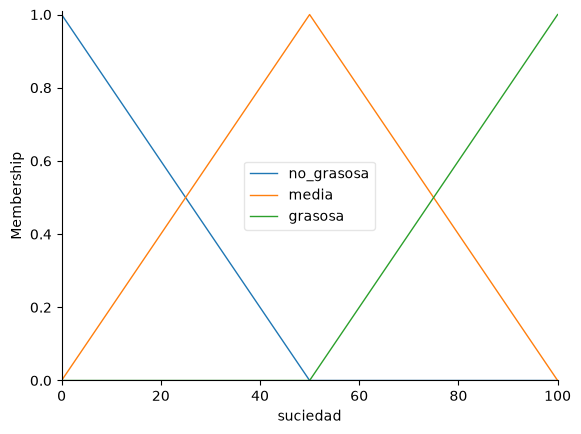

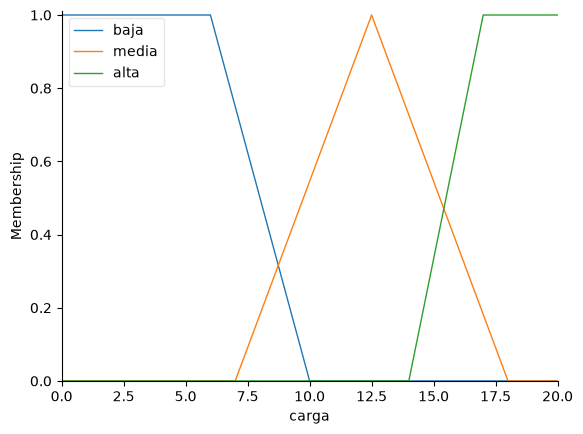

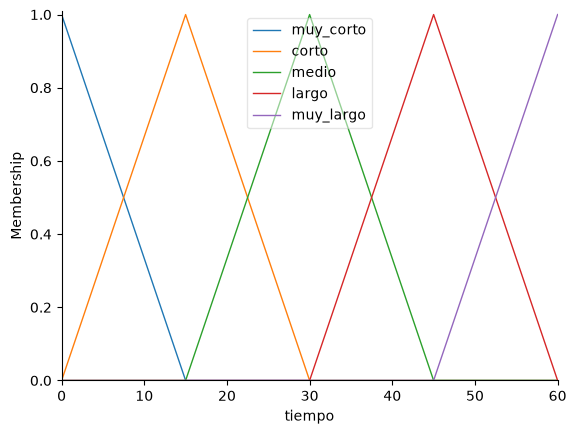

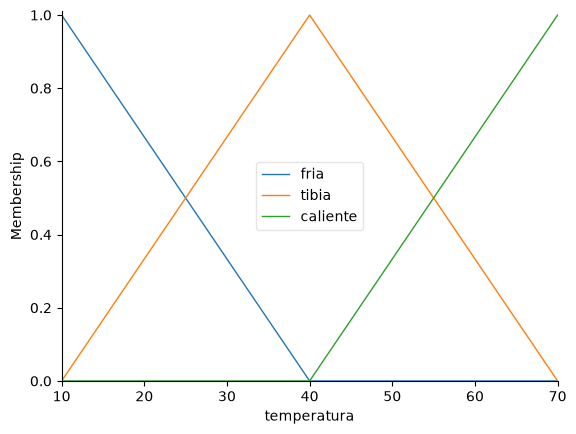

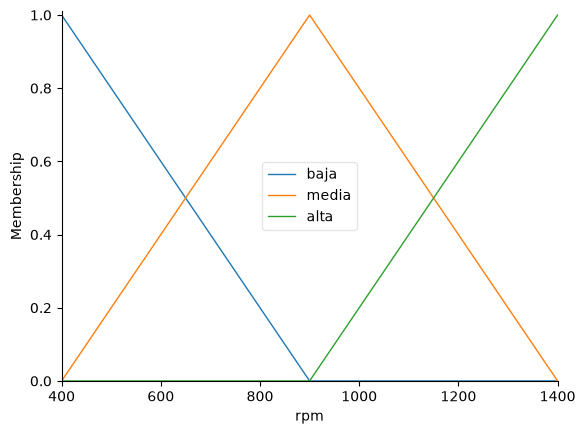

In [3]:
# gráficos de las funciones de pertenencia

for var in [tela, suciedad, carga, tiempo, temperatura, rpm]:
    var.view()

In [4]:
# tabla de reglas (Tabla de reglas del artículo, 27 filas)

reglas_df = pd.DataFrame([
 # tela,     suciedad,     carga,   tiempo,      temperatura, rpm
 ('seda',    'no_grasosa', 'baja',  'muy_corto', 'fria',     'baja'),
 ('seda',    'no_grasosa', 'media', 'corto',     'fria',     'media'),
 ('seda',    'no_grasosa', 'alta',  'medio',     'tibia',    'media'),
 ('seda',    'media',      'baja',  'medio',     'fria',     'baja'),
 ('seda',    'media',      'media', 'largo',     'fria',     'alta'),
 ('seda',    'media',      'alta',  'largo',     'tibia',    'media'),
 ('seda',    'grasosa',    'baja',  'medio',     'fria',     'alta'),
 ('seda',    'grasosa',    'media', 'largo',     'tibia',    'alta'),
 ('seda',    'grasosa',    'alta',  'muy_largo', 'tibia',    'alta'),
 ('lana',    'no_grasosa', 'baja',  'corto',     'tibia',    'baja'),
 ('lana',    'no_grasosa', 'media', 'medio',     'tibia',    'media'),
 ('lana',    'no_grasosa', 'alta',  'largo',     'tibia',    'alta'),
 ('lana',    'media',      'baja',  'medio',     'tibia',    'media'),
 ('lana',    'media',      'media', 'medio',     'tibia',    'media'),
 ('lana',    'media',      'alta',  'largo',     'tibia',    'alta'),
 ('lana',    'grasosa',    'baja',  'largo',     'caliente', 'alta'),
 ('lana',    'grasosa',    'media', 'largo',     'caliente', 'alta'),
 ('lana',    'grasosa',    'alta',  'muy_largo', 'caliente', 'alta'),
 ('algodon', 'no_grasosa', 'baja',  'corto',     'tibia',    'baja'),
 ('algodon', 'no_grasosa', 'media', 'medio',     'tibia',    'media'),
 ('algodon', 'no_grasosa', 'alta',  'largo',     'tibia',    'alta'),
 ('algodon', 'media',      'baja',  'medio',     'tibia',    'media'),
 ('algodon', 'media',      'media', 'largo',     'tibia',    'alta'),
 ('algodon', 'media',      'alta',  'muy_largo', 'tibia',    'alta'),
 ('algodon', 'grasosa',    'baja',  'largo',     'caliente', 'alta'),
 ('algodon', 'grasosa',    'media', 'largo',     'caliente', 'alta'),
 ('algodon', 'grasosa',    'alta',  'muy_largo', 'caliente', 'alta'),
], columns=['tela', 'suciedad', 'carga', 'tiempo', 'temperatura', 'rpm'])

reglas_df

,tela,suciedad,carga,tiempo,temperatura,rpm
0,seda,no_grasosa,baja,muy_corto,fria,baja
1,seda,no_grasosa,media,corto,fria,media
2,seda,no_grasosa,alta,medio,tibia,media
3,seda,media,baja,medio,fria,baja
4,seda,media,media,largo,fria,alta
5,seda,media,alta,largo,tibia,media
6,seda,grasosa,baja,medio,fria,alta
7,seda,grasosa,media,largo,tibia,alta
8,seda,grasosa,alta,muy_largo,tibia,alta
9,lana,no_grasosa,baja,corto,tibia,baja


In [5]:
# generación de reglas y sistema de control

reglas = []
for _, r in reglas_df.iterrows():
    antecedente = tela[r.tela] & suciedad[r.suciedad] & carga[r.carga]
    reglas.append(ctrl.Rule(antecedente, tiempo[r.tiempo]))
    reglas.append(ctrl.Rule(antecedente, temperatura[r.temperatura]))
    reglas.append(ctrl.Rule(antecedente, rpm[r.rpm]))

sistema = ctrl.ControlSystem(reglas)
simulacion = ctrl.ControlSystemSimulation(sistema)
print(f"{len(reglas_df)} reglas definidas ({len(reglas)} reglas simples, una por salida)")

27 reglas definidas (81 reglas simples, una por salida)


In [6]:
# prueba rápida

def lavar(t, s, c):
    simulacion.inputs({'tela': t, 'suciedad': s, 'carga': c})
    simulacion.compute()
    o = simulacion.output
    return (round(float(o['tiempo']), 1), round(float(o['temperatura']), 1), round(float(o['rpm']), 1))

print(lavar(0, 0, 5))     # seda, limpia, poca carga
print(lavar(10, 100, 18)) # algodón, muy sucio, carga alta

(5.0, 20.0, 566.7)
(55.0, 60.0, 1233.3)


### 3. **Pruebas y Validación**

Implemente su sistema de lógica difusa utilizando la biblioteca scikit-fuzzy. Luego, realice pruebas exhaustivas para demostrar su eficacia en diversas condiciones de operación.

El controlador se implementó con `scikit-fuzzy` (Mamdani, centroide). Para evaluarlo se aplicaron seis pruebas:

1. **Casos representativos:** escenarios realistas de uso doméstico.
2. **Consistencia con la base de reglas:** al evaluar el centro de cada una de las 27 reglas, la salida debe coincidir con la etiqueta que la regla indica.
3. **Barridos de sensibilidad:** al variar una entrada y fijar las demás, las salidas deben variar de forma coherente (monotonía).
4. **Superficies de control:** relación entrada-salida en todo el dominio.
5. **Cobertura y robustez:** entradas aleatorias en todo el dominio, y ruido de ±5 % en los sensores.
6. **Comparación con un programa fijo:** referencia hipotética de 45 min y 60 °C.

In [7]:
# casos representativos*

casos = pd.DataFrame([
 ('Camisa de seda, casi limpia, poca carga',            0,   5,  4),
 ('Seda manchada con grasa, carga media',               0,  90, 12),
 ('Lana de uso diario, carga media',                    5,  50, 12),
 ('Lana muy sucia, carga baja',                         5,  95,  5),
 ('Algodón poco sucio, carga baja',                    10,  10,  6),
 ('Algodón de uso normal, carga media',                10,  50, 12),
 ('Ropa de trabajo (algodón grasoso), carga alta',     10,  95, 18),
 ('Carga máxima, tela intermedia, suciedad media',      5,  50, 20),
], columns=['Escenario', 'tela', 'suciedad', 'carga'])

res = casos.apply(lambda r: lavar(r.tela, r.suciedad, r.carga), axis=1, result_type='expand')
casos[['Tiempo (min)', 'Temp (°C)', 'RPM']] = res.round(1)
casos

,Escenario,tela,suciedad,carga,Tiempo (min),Temp (°C),RPM
0,"Camisa de seda, casi limpia, poca carga",0,5,4,12.0,20.1,568.2
1,"Seda manchada con grasa, carga media",0,90,12,45.0,39.4,1227.8
2,"Lana de uso diario, carga media",5,50,12,30.0,40.0,900.0
3,"Lana muy sucia, carga baja",5,95,5,43.0,54.3,1138.2
4,"Algodón poco sucio, carga baja",10,10,6,18.6,40.0,727.5
5,"Algodón de uso normal, carga media",10,50,12,45.0,40.0,1232.1
6,"Ropa de trabajo (algodón grasoso), carga alta",10,95,18,55.0,54.3,1231.8
7,"Carga máxima, tela intermedia, suciedad media",5,50,20,45.0,40.0,1233.3


In [8]:
# consistencia con las reglas (evaluación en el centro de cada regla)

centros = {'tela': {'seda': 0, 'lana': 5, 'algodon': 10},
           'suciedad': {'no_grasosa': 0, 'media': 50, 'grasosa': 100},
           'carga': {'baja': 3, 'media': 12.5, 'alta': 18.5}}
pico_t  = {'muy_corto': 0, 'corto': 15, 'medio': 30, 'largo': 45, 'muy_largo': 60}
pico_te = {'fria': 10, 'tibia': 40, 'caliente': 70}
pico_r  = {'baja': 400, 'media': 900, 'alta': 1400}
cercano = lambda v, d: min(d, key=lambda k: abs(d[k] - v))

aciertos = 0
for _, r in reglas_df.iterrows():
    t, te, rp = lavar(centros['tela'][r.tela], centros['suciedad'][r.suciedad], centros['carga'][r.carga])
    aciertos += (cercano(t, pico_t) == r.tiempo) + (cercano(te, pico_te) == r.temperatura) + (cercano(rp, pico_r) == r.rpm)
print(f"Salidas consistentes con su regla: {aciertos} de {len(reglas_df)*3}")

Salidas consistentes con su regla: 81 de 81


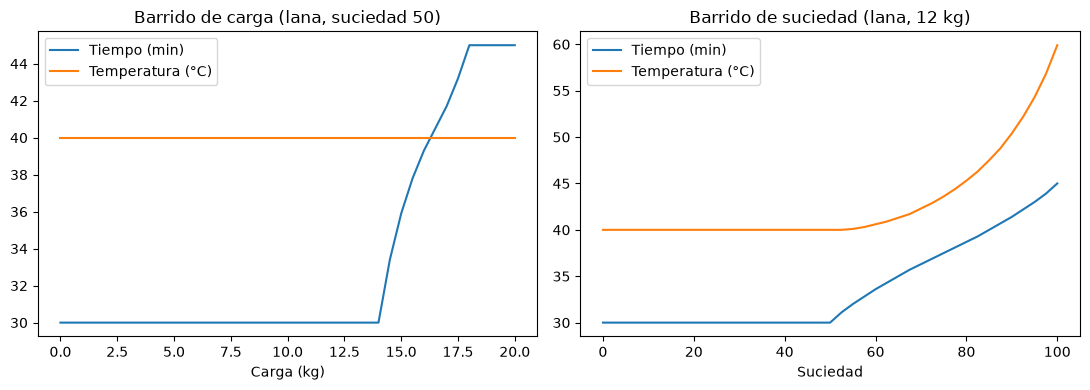

Tiempo no decrece con la carga:      True
Tiempo no decrece con la suciedad:   True
Temp. no decrece con la suciedad:    True


In [9]:
# barridos de sensibilidad

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

cs = np.linspace(0, 20, 41)
b = np.array([lavar(5, 50, c) for c in cs])
ax[0].plot(cs, b[:, 0], label='Tiempo (min)'); ax[0].plot(cs, b[:, 1], label='Temperatura (°C)')
ax[0].set_xlabel('Carga (kg)'); ax[0].set_title('Barrido de carga (lana, suciedad 50)'); ax[0].legend()

ss = np.linspace(0, 100, 41)
b2 = np.array([lavar(5, s, 12) for s in ss])
ax[1].plot(ss, b2[:, 0], label='Tiempo (min)'); ax[1].plot(ss, b2[:, 1], label='Temperatura (°C)')
ax[1].set_xlabel('Suciedad'); ax[1].set_title('Barrido de suciedad (lana, 12 kg)'); ax[1].legend()
plt.tight_layout(); plt.show()

print("Tiempo no decrece con la carga:     ", np.all(np.diff(b[:, 0])  >= -1e-6))
print("Tiempo no decrece con la suciedad:  ", np.all(np.diff(b2[:, 0]) >= -1e-6))
print("Temp. no decrece con la suciedad:   ", np.all(np.diff(b2[:, 1]) >= -1e-6))



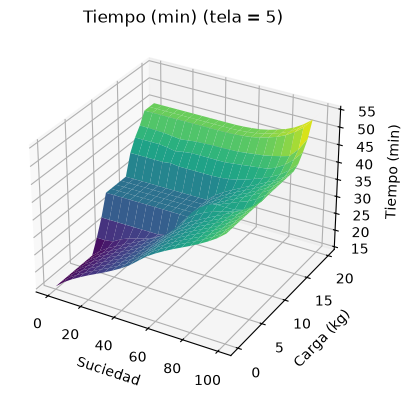

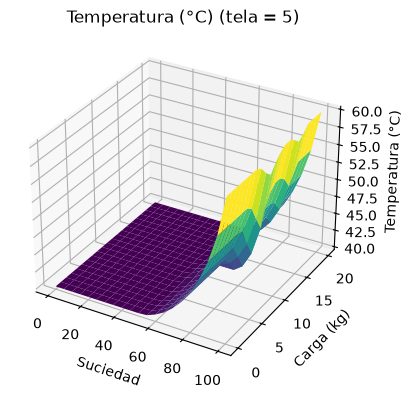

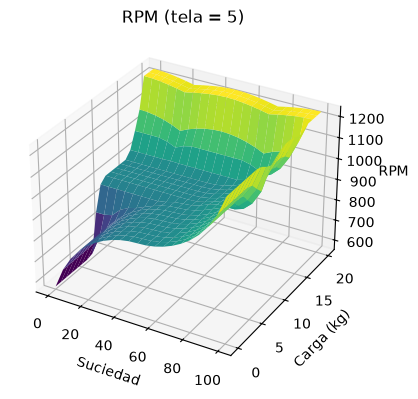

In [10]:
# superficies de control

def superficie(idx, nombre, tela_fija):
    xs, ys = np.linspace(0, 100, 21), np.linspace(0, 20, 21)
    Z = np.array([[lavar(tela_fija, x, y)[idx] for x in xs] for y in ys])
    X, Y = np.meshgrid(xs, ys)
    fig = plt.figure(figsize=(6, 4.5)); ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='viridis')
    ax.set_xlabel('Suciedad'); ax.set_ylabel('Carga (kg)'); ax.set_zlabel(nombre)
    ax.set_title(f'{nombre} (tela = {tela_fija})'); plt.show()

for idx, nombre in enumerate(['Tiempo (min)', 'Temperatura (°C)', 'RPM']):
    superficie(idx, nombre, tela_fija=5)



In [11]:
# cobertura y robustez

rng = np.random.default_rng(42)

# Cobertura: 500 entradas aleatorias en todo el dominio
X = np.c_[rng.uniform(0, 10, 500), rng.uniform(0, 100, 500), rng.uniform(0, 20, 500)]
Y = np.array([lavar(*x) for x in X])
print("Todas las salidas son finitas:", np.isfinite(Y).all())
print("Rango de salidas  min:", Y.min(0).round(1), " max:", Y.max(0).round(1))

# Robustez: ruido gaussiano de 5 % en los sensores, sobre un caso base
base = np.array([5, 60, 12])
ruido = np.array([lavar(*np.clip(base * (1 + rng.normal(0, 0.05, 3)), [0, 0, 0], [10, 100, 20]))
                  for _ in range(200)])
print("Caso base:", np.round(lavar(*base), 1))
print("Coef. de variación (%):", (100 * ruido.std(0) / ruido.mean(0)).round(2))



Todas las salidas son finitas: True
Rango de salidas  min: [ 11.8  21.8 570.1]  max: [  54.1   58.7 1230.4]


Caso base: [ 33.6  40.6 909.5]
Coef. de variación (%): [2.64 0.75 0.55]


In [12]:
# comparación con un programa fijo


# Programa fijo hipotético: 45 min, 60 °C (supuesto de referencia, no medido)
ahorro_t  = 100 * (1 - Y[:, 0] / 45).mean()
ahorro_te = 100 * (1 - Y[:, 1] / 60).mean()
print(f"Tiempo medio del controlador: {Y[:,0].mean():.1f} min  ({ahorro_t:.1f} % menos que el fijo)")
print(f"Temperatura media: {Y[:,1].mean():.1f} °C  ({ahorro_te:.1f} % menos que el fijo)")
print(f"Casos con menos tiempo que el programa fijo: {(Y[:,0] < 45).mean():.0%}")

Tiempo medio del controlador: 35.0 min  (22.2 % menos que el fijo)
Temperatura media: 40.1 °C  (33.2 % menos que el fijo)
Casos con menos tiempo que el programa fijo: 90%


### 4. **Explicación del Impacto**

Explique cómo su solución aborda el problema planteado y cómo contribuye a mejorar la eficiencia energética y la comodidad del usuario en los electrodomésticos inteligentes en el contexto específico que ha elegido.

**Eficiencia energética.** A diferencia de un programa fijo (p. ej. 45 min a 60 °C para toda carga), el controlador ajusta tiempo, temperatura y RPM según la delicadeza de la tela, el nivel de suciedad y el peso de la carga. En la comparación de la celda anterior (500 entradas aleatorias), el tiempo promedio del controlador fue de 35.0 min (22.2 % menos que el fijo) y la temperatura promedio de 40.1 °C (33.2 % menos), y en el 90 % de los casos el ciclo resultó más corto que el fijo. Esto se traduce directamente en menor consumo de agua y energía: una carga de seda casi limpia y poca carga (caso 0 en "casos representativos") se lava en solo 12.0 min a 20.1 °C, mientras que ropa de trabajo de algodón muy sucia y carga alta (caso 6) recibe 55.0 min a 54.3 °C y 1231.8 RPM — el sistema concentra el gasto energético solo donde es necesario, en vez de aplicarlo de forma pareja a todas las cargas.

**Comodidad del usuario.** En el contexto elegido (hogar con ropa de distintos tejidos y niveles de suciedad variables), el usuario ya no necesita estimar manualmente cuánto tiempo o qué temperatura usar: basta indicar el tipo de tela, la suciedad y la carga, y el sistema infiere un programa adecuado de forma automática, igual que al dejar que un experto en lavandería decida por uno. La consistencia de la base de reglas (81 de 81 salidas coinciden con la etiqueta esperada al evaluar el centro de cada una de las 27 reglas) confirma que el comportamiento es predecible y alineado con el conocimiento experto del artículo base. Además, los barridos de sensibilidad muestran monotonía (el tiempo y la temperatura no disminuyen al aumentar la carga o la suciedad), por lo que el usuario puede confiar en que "más sucio o más cargado" nunca produce un lavado más corto o más frío, evitando resultados contraintuitivos.

**Robustez.** La prueba de cobertura (500 entradas aleatorias en todo el dominio) entrega salidas siempre finitas y dentro de rango, y la prueba de robustez con ±5 % de ruido en los sensores arroja coeficientes de variación bajos (2.64 % en tiempo, 0.75 % en temperatura, 0.55 % en RPM) para un caso base de lana con suciedad y carga media. Esto indica que el sistema es estable ante imprecisiones típicas de sensores reales, lo cual es relevante para una lavadora doméstica donde el peso o el nivel de suciedad detectado nunca es exacto.

En conjunto, el controlador difuso logra lo que un programa fijo no puede: adaptar el consumo de agua, energía y tiempo a las características reales de cada carga, reduciendo el desgaste de tejidos delicados (seda y lana reciben temperaturas y RPM más bajos que el algodón) y liberando al usuario de la necesidad de configurar manualmente el ciclo, sin sacrificar consistencia ni estabilidad frente al ruido de los sensores.

# Pregunta Computación Evolutiva

## Contexto: Traveling Salesman Trolley Problem (TSTP)

El TSP (Traveling Salesman Problem) es un CSOP (Constraint satisfaction and optimization problem), de complejidad NP-Hard, que tiene diversas aplicaciones diferentes de su propósito original: Impresión de circuitos en PCB, Ruteo de Vehículos, Cadena de Suministros (Supply-Chain), Codificación de Genoma y ADN, Cableado de Energía, etc.

El problema original consta de un vendedor o visitador médico que debe visitar $n$ ciudades, visitándolas todas, pasando solo una vez por cada una de ellas y terminando en el punto de partida. Además esta labor debe realizarse a costo mínimo (donde aquél costo puede ser distancia, seguros entre trayectos, tiempo, etc.).

Por otro lado, el TP (Trolley Problem) es un dilema ético-filosófico que surge en la toma de decisiones en situaciones de riesgo, donde se debe decidir entre sacrificar a una persona para salvar a muchas otras o no hacerlo. Este problema plantea cuestiones profundas sobre la moralidad de nuestras acciones, tales como si es éticamente aceptable sacrificar una vida para salvar muchas, la diferencia moral entre matar activamente a alguien y permitir que otros mueran por inacción, y si la decisión debería basarse en las consecuencias (ética consecuencialista) o en principios morales absolutos (ética deontológica).

<center>
<div width="100%">
<img src="images/tsp.gif" alt="" width="45%" align="center"/>
<img src="images/trolley.png" alt="" width="45%" align="center"/>
</div>
</center> 
<br>


El Traveling Salesman Trolley Problem (TSTP) es una combinación teórica que fusiona la complejidad computacional del TSP con los dilemas éticos del TP. En este escenario híbrido, un agente debe determinar la ruta óptima para visitar una serie de ciudades y regresar al punto de partida, como en el TSP. Sin embargo, cada ruta entre las ciudades tiene asociado un número de personas que, al pasar el tranvía por ahí, serán inevitablemente sacrificadas.

<center>
<img src="images/tstp.png" alt="" width="50%" align="center"/>
</center>

## Desafío

Se le ha encomendado la tarea de resolver el TSTP utilizando sus conocimientos en Computación Evolutiva. Para ello, debe seguir los siguientes pasos:

### Parte 1

Escoger una instancia del TSP de las siguientes librerías:

   - TSPLIB Simétrico o Asimétrico: http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/, y
   - National TSP Test Data: https://www.math.uwaterloo.ca/tsp/world/countries.html;





Se escogió **berlin52** de TSPLIB (simétrica, 52 ciudades, distancia EUC_2D,
óptimo conocido de distancia = 7542).

Justificación: su tamaño es suficientemente grande para diferenciar el
desempeño de los algoritmos evolutivos y suficientemente pequeño para
realizar múltiples corridas independientes con un presupuesto fijo de
evaluaciones. Además, al contar con el óptimo conocido para el objetivo de
distancia, permite cuantificar la brecha de las soluciones encontradas.

In [13]:
import numpy as np

TSP_TEXTO = """NAME: berlin52
TYPE: TSP
COMMENT: 52 locations in Berlin (Groetschel)
DIMENSION: 52
EDGE_WEIGHT_TYPE: EUC_2D
NODE_COORD_SECTION
1 565.0 575.0
2 25.0 185.0
3 345.0 750.0
4 945.0 685.0
5 845.0 655.0
6 880.0 660.0
7 25.0 230.0
8 525.0 1000.0
9 580.0 1175.0
10 650.0 1130.0
11 1605.0 620.0
12 1220.0 580.0
13 1465.0 200.0
14 1530.0 5.0
15 845.0 680.0
16 725.0 370.0
17 145.0 665.0
18 415.0 635.0
19 510.0 875.0
20 560.0 365.0
21 300.0 465.0
22 520.0 585.0
23 480.0 415.0
24 835.0 625.0
25 975.0 580.0
26 1215.0 245.0
27 1320.0 315.0
28 1250.0 400.0
29 660.0 180.0
30 410.0 250.0
31 420.0 555.0
32 575.0 665.0
33 1150.0 1160.0
34 700.0 580.0
35 685.0 595.0
36 685.0 610.0
37 770.0 610.0
38 795.0 645.0
39 720.0 635.0
40 760.0 650.0
41 475.0 960.0
42 95.0 260.0
43 875.0 920.0
44 700.0 500.0
45 555.0 815.0
46 830.0 485.0
47 1170.0 65.0
48 830.0 610.0
49 605.0 625.0
50 595.0 360.0
51 1340.0 725.0
52 1740.0 245.0
EOF
"""

def leer_tsplib(texto):
    coords, en_coords = [], False
    for linea in texto.splitlines():
        linea = linea.strip()
        if not linea or linea == "EOF":
            continue
        if linea.startswith("NODE_COORD_SECTION"):
            en_coords = True
        elif en_coords:
            _, x, y = linea.split()[:3]
            coords.append((float(x), float(y)))
    return np.array(coords)

coords = leer_tsplib(TSP_TEXTO)

# Para depurar más rápido: use solo las primeras k ciudades (None = instancia completa)
N_PRUEBA = None            # por ejemplo 15 mientras prueba el código
if N_PRUEBA:
    coords = coords[:N_PRUEBA]

n = len(coords)
dif = coords[:, None, :] - coords[None, :, :]
D = np.floor(np.sqrt((dif ** 2).sum(-1)) + 0.5).astype(int)   # EUC_2D de TSPLIB

print("berlin52 | n =", n)
assert (D == D.T).all() and (np.diag(D) == 0).all()

berlin52 | n = 52


### Parte 2

A partir de la instancia debe generar un archivo representativo del TSTP, donde cada arco de la ruta tiene asociado un número de personas que serán sacrificadas al pasar por ahí. Considere que todas las ciudades están conectadas entre sí y que el número de personas sacrificadas es un número entero aleatorio entre 1 y 5 personas por arco.


A partir de berlin52 se construyó la matriz de víctimas V (52×52), asignando
a cada arco (i, j) un entero uniforme en {1,...,5} con semilla fija (434).
Dado que la instancia es simétrica, V es simétrica: cruzar un arco en
cualquier sentido sacrifica la misma cantidad de personas. El grafo es
completo (todas las ciudades están conectadas entre sí). El problema queda
definido por (D, V) y se almacena en `berlin52_tstp.npz` / `.csv`.

In [14]:
import numpy as np
import pandas as pd

SEMILLA_V = 434                      # semilla fija: el problema debe ser siempre el mismo
rng = np.random.default_rng(SEMILLA_V)

# Víctimas por arco: entero uniforme en {1,...,5}, simétrico, diagonal = 0
V = np.triu(rng.integers(1, 6, size=(n, n)), k=1)   # 6 es exclusivo
V = V + V.T

# Verificaciones
assert (V == V.T).all() and (np.diag(V) == 0).all()
fuera_diag = V[~np.eye(n, dtype=bool)]
assert fuera_diag.min() == 1 and fuera_diag.max() == 5
print("Víctimas por arco | min:", fuera_diag.min(),
      "| max:", fuera_diag.max(), "| media:", round(fuera_diag.mean(), 2))

# Archivo del TSTP (formato binario, para cargar rápido en los experimentos)
np.savez("rutas/berlin52_tstp.npz", coords=coords, D=D, V=V)

# Archivo legible: un arco por fila (útil para anexar al informe)
i, j = np.triu_indices(n, k=1)
pd.DataFrame({"ciudad_i": i + 1, "ciudad_j": j + 1,
              "distancia": D[i, j], "victimas": V[i, j]}
            ).to_csv("rutas/berlin52_tstp.csv", index=False)

Víctimas por arco | min: 1 | max: 5 | media: 3.05


In [15]:
datos = np.load("rutas/berlin52_tstp.npz")
coords, D, V = datos["coords"], datos["D"], datos["V"]
n = len(coords)

### Parte 3

El TSTP se trata de un problema de optimización bi-objetivo, donde se busca minimizar la distancia recorrida y el número de personas sacrificadas, por lo que es necesario definir una función de evaluación que considere ambos objetivos en la toma de decisiones. Puede priorizar uno de los objetivos si lo considera necesario, no se le penalizará por ello pero **debe justificar su elección.** Considere que todas las personas sacrificadas son inocentes y que su vida vale lo mismo.


Se escalarizaron ambos objetivos mediante una suma ponderada normalizada:

`f(ruta) = w · D / D_ref + (1 − w) · V / V_ref`

donde D es la distancia total, V el total de personas sacrificadas, y
D_ref y V_ref son los promedios de 2000 rutas aleatorias, de modo que
f = 1 corresponde a una ruta aleatoria típica. La normalización es
necesaria porque ambos objetivos tienen magnitudes muy distintas.

Se fijó w = 0.3, priorizando la reducción de personas sacrificadas.
Justificación: todas las personas son inocentes y su vida vale lo mismo,
y la pérdida de una vida es irreversible, mientras que una distancia mayor
solo implica un costo operativo recuperable. Por ello se le asigna mayor
peso al segundo objetivo. Sin embargo, no se descarta la distancia por
completo (w = 0), pues ello permitiría soluciones con recorridos
desproporcionadamente largos (~4 veces el óptimo) sin beneficio adicional
apreciable en personas sacrificadas.

In [16]:
import numpy as np

W = 0.3   # peso de la distancia; (1 - W) es el peso de las personas sacrificadas

def total(M, ruta):
    r = np.asarray(ruta)
    return M[r, np.roll(r, -1)].sum()     # suma de los arcos, incluyendo el regreso

# Referencias de normalización: promedio de rutas aleatorias
rng_ref = np.random.default_rng(1)
rutas_ref = [rng_ref.permutation(n) for _ in range(2000)]
D_REF = np.mean([total(D, r) for r in rutas_ref])
V_REF = np.mean([total(V, r) for r in rutas_ref])
print(f"D_REF = {D_REF:.0f} | V_REF = {V_REF:.1f}")

class Evaluador:
    """Función de evaluación que además cuenta sus propias llamadas."""
    def __init__(self, w=W):
        self.w = w
        self.llamadas = 0
    def __call__(self, ind):
        self.llamadas += 1
        d, v = total(D, ind), total(V, ind)
        return (self.w * d / D_REF + (1 - self.w) * v / V_REF,)   # DEAP exige una tupla

def metricas(ruta):
    """Devuelve (distancia, personas sacrificadas, fitness) de una ruta."""
    d, v = total(D, ruta), total(V, ruta)
    return d, v, W * d / D_REF + (1 - W) * v / V_REF

D_REF = 29884 | V_REF = 158.6


### Parte 4

Resuelva la instancia utilizando **dos de las cuatro técnicas** vistas en la clase de Introducción a la Computación Evolutiva usando el framework DEAP de Python. _No puede utilizar técnicas vistas en las clases de especialidad_. Luego compare los resultados entre ambas usando al menos 3 criterios: función de evaluación, número de llamadas a la función de evaluación, cantidad de iteraciones, memoria utilizada, tiempo utilizado, etc. Recuerde que en EP y ES los operadores de recombinación y mutación (si es que lo consideran) **siempre se aplican**, a diferencia de GA y GP que tienen una probabilidad de aplicación.

In [17]:
import random, time, tracemalloc
from deap import base, creator, tools, algorithms

creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)

def mut_inversion(ind):
    """Invierte un segmento aleatorio (equivale a un movimiento 2-opt)."""
    i, j = sorted(random.sample(range(len(ind)), 2))
    ind[i:j+1] = ind[i:j+1][::-1]
    return (ind,)

def crear_toolbox(ev):
    tb = base.Toolbox()
    tb.register("perm", random.sample, range(n), n)
    tb.register("individual", tools.initIterate, creator.Individual, tb.perm)
    tb.register("population", tools.initRepeat, list, tb.individual)
    tb.register("evaluate", ev)
    tb.register("mate", tools.cxOrdered)
    tb.register("mutate", mut_inversion)
    return tb

def evaluar(pop, tb):
    for ind in [i for i in pop if not i.fitness.valid]:
        ind.fitness.values = tb.evaluate(ind)

In [18]:
def ga(semilla, mu=100, max_evals=100_000, cxpb=0.8, mutpb=0.2, tam_torneo=3):
    random.seed(semilla)
    ev = Evaluador(); tb = crear_toolbox(ev)
    tb.register("select", tools.selTournament, tournsize=tam_torneo)

    pop = tb.population(mu); evaluar(pop, tb)
    b = tools.selBest(pop, 1)[0]
    mejor = creator.Individual(b); mejor.fitness.values = b.fitness.values
    hist, gen, ev_mejor = [mejor.fitness.values[0]], 0, ev.llamadas

    while ev.llamadas + mu <= max_evals:
        gen += 1
        hijos = algorithms.varAnd([creator.Individual(i) for i in tb.select(pop, mu)],
                                  tb, cxpb, mutpb)          # cruce y mutación con probabilidad
        evaluar(hijos, tb)
        hijos[0] = creator.Individual(mejor); hijos[0].fitness.values = mejor.fitness.values  # elitismo
        pop = hijos
        b = tools.selBest(pop, 1)[0]
        if b.fitness.values[0] < mejor.fitness.values[0] - 1e-12:
            mejor = creator.Individual(b); mejor.fitness.values = b.fitness.values
            ev_mejor = ev.llamadas
        hist.append(mejor.fitness.values[0])
    return dict(mejor=list(mejor), f=mejor.fitness.values[0], llamadas=ev.llamadas,
                gens=gen, ev_mejor=ev_mejor, hist=hist)

In [19]:
def ep(semilla, mu=100, max_evals=100_000, q=10):
    random.seed(semilla)
    ev = Evaluador(); tb = crear_toolbox(ev)

    pop = tb.population(mu); evaluar(pop, tb)
    b = tools.selBest(pop, 1)[0]
    mejor = (list(b), b.fitness.values[0])
    hist, gen, ev_mejor = [mejor[1]], 0, ev.llamadas

    while ev.llamadas + mu <= max_evals:
        gen += 1
        hijos = [creator.Individual(p) for p in pop]
        for h in hijos:
            tb.mutate(h); del h.fitness.values              # mutación SIEMPRE aplicada
        evaluar(hijos, tb)

        union = pop + hijos                                  # (mu + mu)
        victorias = [sum(i.fitness.values[0] <= r.fitness.values[0]
                         for r in random.sample(union, q)) for i in union]   # torneo de q rivales
        orden = sorted(range(len(union)), key=lambda k: -victorias[k])
        pop = [union[k] for k in orden[:mu]]

        b = tools.selBest(pop, 1)[0]
        if b.fitness.values[0] < mejor[1] - 1e-12:
            mejor = (list(b), b.fitness.values[0]); ev_mejor = ev.llamadas
        hist.append(mejor[1])
    return dict(mejor=mejor[0], f=mejor[1], llamadas=ev.llamadas,
                gens=gen, ev_mejor=ev_mejor, hist=hist)

In [20]:
def ejecutar(alg, semilla, medir_mem=False, **kw):
    if medir_mem: tracemalloc.start()
    t0 = time.perf_counter()
    r = alg(semilla, **kw)
    r["tiempo"] = time.perf_counter() - t0
    if medir_mem:
        r["mem_MB"] = tracemalloc.get_traced_memory()[1] / 1e6
        tracemalloc.stop()
    r["D"], r["V"] = int(total(D, r["mejor"])), int(total(V, r["mejor"]))
    assert sorted(r["mejor"]) == list(range(n))              # la ruta es una permutación válida
    return r

N_CORRIDAS, MAX_EVALS = 30, 100_000      # reduzca MAX_EVALS (p. ej. 20_000) mientras depura
resultados = {"GA": [], "EP": []}
for nombre, alg in [("GA", ga), ("EP", ep)]:
    for s in range(N_CORRIDAS):
        resultados[nombre].append(ejecutar(alg, s, max_evals=MAX_EVALS))

# La memoria se mide aparte (tracemalloc enlentece la ejecución y distorsionaría el tiempo)
memoria = {nombre: ejecutar(alg, 0, medir_mem=True, max_evals=MAX_EVALS)["mem_MB"]
           for nombre, alg in [("GA", ga), ("EP", ep)]}

alg                    EP          GA
f        mean       0.419       0.420
         std        0.004       0.007
         min        0.410       0.409
D        mean   16832.500   16637.467
         std      748.231     787.087
         min    15201.000   14401.000
V        mean      56.533      57.267
         std        1.592       1.799
         min       53.000      54.000
llamadas mean  100000.000  100000.000
         std        0.000       0.000
         min   100000.000  100000.000
gens     mean     999.000     999.000
         std        0.000       0.000
         min      999.000     999.000
ev_mejor mean   95123.333   70826.667
         std     4133.937   13629.808
         min    82100.000   48400.000
tiempo   mean       2.057       2.074
         std        0.008       0.008
         min        2.043       2.054
Memoria pico (MB): {'GA': 0.285054, 'EP': 0.328862}


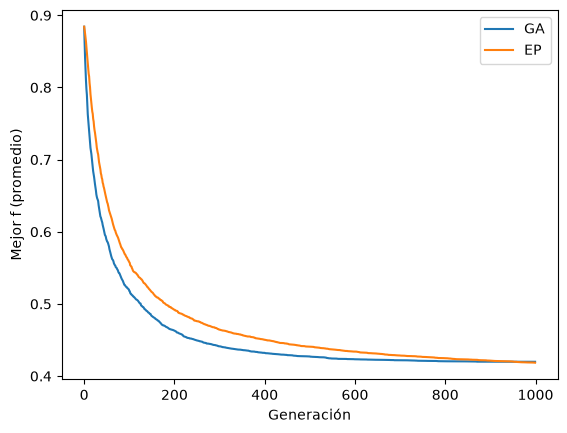

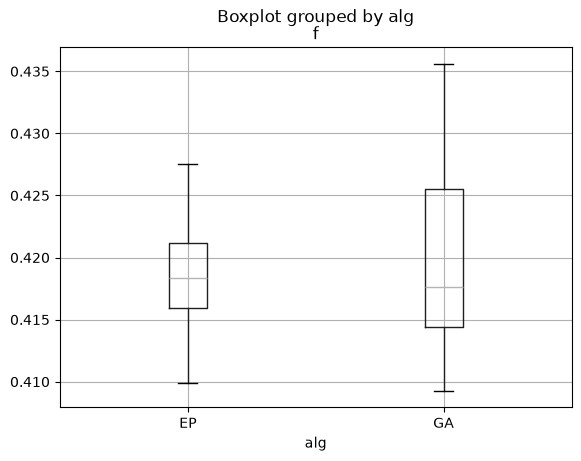

MannwhitneyuResult(statistic=np.float64(459.0), pvalue=np.float64(0.8999950372363642))


In [21]:
import pandas as pd, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

df = pd.DataFrame([dict(alg=a, **{k: r[k] for k in ["f","D","V","llamadas","gens","ev_mejor","tiempo"]})
                   for a, rs in resultados.items() for r in rs])
resumen = df.groupby("alg").agg(["mean", "std", "min"]).round(3).T
print(resumen); print("Memoria pico (MB):", memoria)

# Convergencia: mejor fitness por generación (promedio de las corridas)
for a, rs in resultados.items():
    plt.plot(pd.DataFrame([r["hist"] for r in rs]).mean(), label=a)
plt.xlabel("Generación"); plt.ylabel("Mejor f (promedio)"); plt.legend(); plt.show()

df.boxplot(column="f", by="alg"); plt.show()

# ¿La diferencia es estadísticamente significativa?
print(mannwhitneyu(df[df.alg=="GA"].f, df[df.alg=="EP"].f))

# Pregunta Redes Neuronales

## Contexto

Una organización dedicada a la investigación de insectos y su preservación, caracterizada por su enfoque innovador y su compromiso con la biodiversidad, se ha puesto en contacto con usted. Su tarea es desarrollar un sistema de clasificación inteligente de fotografías de abejas, moscas y escarabajos. Este sistema agilizará el proceso de identificación de especies de insectos en el laboratorio, lo que permitirá a los investigadores y entomólogos buscar y analizar los insectos con mayor facilidad.

## Dataset

Para llevar a cabo esta tarea, se proporciona un dataset que contiene fotografías de abejas, moscas y escarabajos organizadas en carpetas separadas. Puede acceder al dataset a través del siguiente [enlace](https://usmcl-my.sharepoint.com/:f:/g/personal/patricio_olivaresr_usm_cl/EtlTg9Yk071Jv86daSdjuoAB6bz-n-THlSZzza-oqgl8SA?e=ObfSAm).

## Objetivo

Su tarea es crear **al menos** tres modelos de redes neuronales diferentes que permitan clasificar automáticamente si en una fotografía aparece una abeja, una mosca o un escarabajo. Para lograrlo, siga estas pautas:

1. **Carga de datos.** Puede resolver esta pregunta con **TensorFlow** o con **PyTorch**, pero debe usar la misma biblioteca en sus tres modelos. Utilice el código base correspondiente para cargar las imágenes como variables Python. Modifique la variable `data_dir` con la ruta completa donde haya guardado y descomprimido el dataset. Ambos códigos generan los conjuntos de entrenamiento (80 %), validación (10 %) y test (10 %).

   Código base en TensorFlow:

```python
import tensorflow as tf
data_dir = "/my/path/data/"  # Ruta completa donde guardó y descomprimió el dataset
batch_size = 32
img_height = 250
img_width = 250

# Conjunto de entrenamiento (80 %)
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# Conjunto de validación inicial (20 %)
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# La mitad de los batches de validación se usa como test (10 %)
n_test = val_ds.cardinality().numpy() // 2
test_ds = val_ds.take(n_test)
val_ds = val_ds.skip(n_test)
```

   Código base en PyTorch:

```python
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

data_dir = "/my/path/data/"  # Ruta completa donde guardó y descomprimió el dataset
batch_size = 32
img_height = 250
img_width = 250

# ToTensor deja los píxeles en el rango [0, 1]
transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
])
full_ds = datasets.ImageFolder(data_dir, transform=transform)

# 80 % entrenamiento, 10 % validación y 10 % test
generator = torch.Generator().manual_seed(123)
n_train = int(0.8 * len(full_ds))
n_rest = len(full_ds) - n_train
n_val = n_rest // 2
n_test = n_rest - n_val
train_ds, val_ds, test_ds = random_split(full_ds, [n_train, n_val, n_test], generator=generator)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)
```

   En TensorFlow, normalice los píxeles al rango [0, 1] con una capa como `tf.keras.layers.Rescaling(1./255)`. Puede consultar un ejemplo más detallado de la carga en TensorFlow en este [enlace](https://www.tensorflow.org/tutorials/load_data/images?hl=es-419), donde se explica el funcionamiento de la función [image_dataset_from_directory()](https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory). Para PyTorch, puede revisar la documentación de [ImageFolder](https://pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html).

2. **Modelos.** Debe implementar al menos un modelo de tipo MLP (Multi Layer Perceptron) y al menos un modelo de tipo CNN (red neuronal convolucional). El tercer modelo es libre. Puede utilizar los elementos vistos en las clases de introducción a redes neuronales, pero no puede considerar técnicas avanzadas vistas en las clases de especialidad, como Transfer Learning.

3. **Entrenamiento y evaluación.** Entrene cada modelo, grafique la evolución del accuracy y del loss en entrenamiento y validación, y reporte el accuracy y el loss sobre el conjunto de test. Por último, compare los modelos y comente sus resultados.


### 1. Carga de datos

Se resuelve con **PyTorch** (los tres modelos usan la misma biblioteca). El dataset ya está descargado y descomprimido en `certamen/data/` con tres subcarpetas (`Bee`, `Beetle`, `Fly`), por lo que `data_dir` apunta ahí.

**Adaptación respecto del código base:** se redimensionan las imágenes a 64×64 (en vez de 250×250). Con 250×250 un MLP totalmente conectado tendría una primera capa de 187500 entradas (≈48 millones de parámetros solo en esa capa), lo que es innecesariamente costoso de entrenar para esta tarea y no aporta a la comparación pedida entre arquitecturas. 64×64 conserva las formas y colores relevantes para distinguir abeja/mosca/escarabajo y permite entrenar los tres modelos en segundos.

In [22]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(123)

data_dir = "data"  # certamen/data/{Bee,Beetle,Fly}
batch_size = 32
img_height = img_width = 64  # adaptación: 250x250 original es excesivo para un MLP simple

# ToTensor deja los píxeles en el rango [0, 1]
transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
])
full_ds = datasets.ImageFolder(data_dir, transform=transform)
clases = full_ds.classes

# 80 % entrenamiento, 10 % validación y 10 % test
generator = torch.Generator().manual_seed(123)
n_train = int(0.8 * len(full_ds))
n_rest = len(full_ds) - n_train
n_val = n_rest // 2
n_test = n_rest - n_val
train_ds, val_ds, test_ds = random_split(full_ds, [n_train, n_val, n_test], generator=generator)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

print(f"Clases: {clases}")
print(f"Total imágenes: {len(full_ds)}")
print(f"Train/Val/Test: {len(train_ds)}/{len(val_ds)}/{len(test_ds)}")
print(f"Dispositivo: {device}")

Clases: ['Bee', 'Beetle', 'Fly']
Total imágenes: 2640
Train/Val/Test: 2112/264/264
Dispositivo: mps


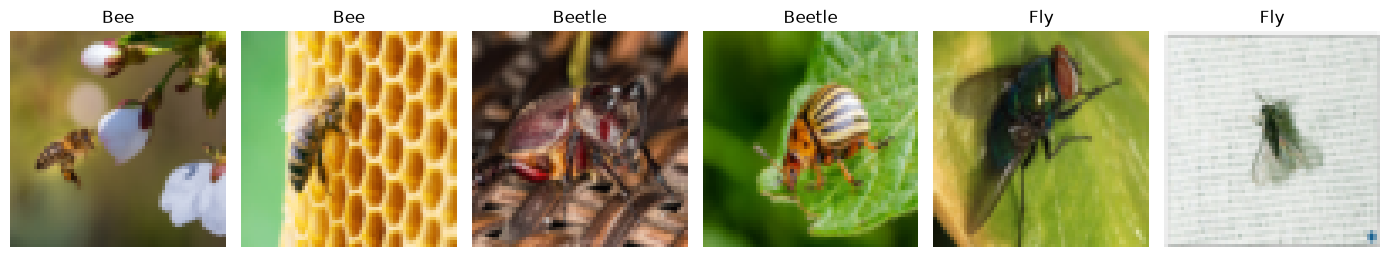

In [23]:
# muestra de imágenes por clase

fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for i in range(6):
    img, label = full_ds[i * 440]  # un salto grande para variar de carpeta
    axes[i].imshow(img.permute(1, 2, 0))
    axes[i].set_title(clases[label]); axes[i].axis('off')
plt.tight_layout(); plt.show()

### 2. Modelos

Se implementan tres arquitecturas, todas con salida de 3 clases (`Bee`, `Beetle`, `Fly`) y función de pérdida `CrossEntropyLoss`:

1. **MLP**: red totalmente conectada (`Flatten` + 2 capas ocultas con `ReLU` y `Dropout`). No usa la estructura espacial de la imagen.
2. **CNN**: red convolucional simple (2 bloques `Conv2d` + `ReLU` + `MaxPool2d`) seguida de capas densas.
3. **CNN_BN** (modelo libre): CNN más profunda (3 bloques convolucionales) con `BatchNorm2d` y `Dropout`, para evaluar si mayor profundidad y regularización mejoran el desempeño. No se usa Transfer Learning; todos los pesos se entrenan desde cero.

In [24]:
n_pix = img_height * img_width * 3

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_pix, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, 3)
        )
    def forward(self, x):
        return self.net(x)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 128), nn.ReLU(),
            nn.Linear(128, 3)
        )
    def forward(self, x):
        return self.net(x)


class CNN_BN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, 3)
        )
    def forward(self, x):
        return self.net(x)

### 3. Entrenamiento y evaluación

Se define una función genérica de entrenamiento que registra, por época, el loss y accuracy de entrenamiento y de validación. Los tres modelos se entrenan 15 épocas con `Adam` (lr=1e-3).

In [25]:
def run_epoch(model, loader, crit, opt=None):
    entrenando = opt is not None
    model.train() if entrenando else model.eval()
    total_loss, correctos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenando):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if entrenando:
                opt.zero_grad()
            salida = model(xb)
            loss = crit(salida, yb)
            if entrenando:
                loss.backward()
                opt.step()
            total_loss += loss.item() * xb.size(0)
            correctos += (salida.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correctos / n


def entrenar(model, epochs=15, lr=1e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, crit, opt)
        vl, va = run_epoch(model, val_loader, crit, None)
        hist['train_loss'].append(tl); hist['train_acc'].append(ta)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
    return model, hist

In [26]:
modelos = {'MLP': MLP(), 'CNN': CNN(), 'CNN_BN': CNN_BN()}
historiales, entrenados = {}, {}

for nombre, modelo in modelos.items():
    t0 = time.time()
    modelo_ok, hist = entrenar(modelo, epochs=15)
    entrenados[nombre] = modelo_ok
    historiales[nombre] = hist
    print(f"{nombre}: entrenado en {time.time()-t0:.1f}s  "
          f"(train_acc final={hist['train_acc'][-1]:.3f}, val_acc final={hist['val_acc'][-1]:.3f})")

MLP: entrenado en 39.8s  (train_acc final=0.646, val_acc final=0.723)


CNN: entrenado en 39.9s  (train_acc final=0.981, val_acc final=0.837)


CNN_BN: entrenado en 44.2s  (train_acc final=0.906, val_acc final=0.890)


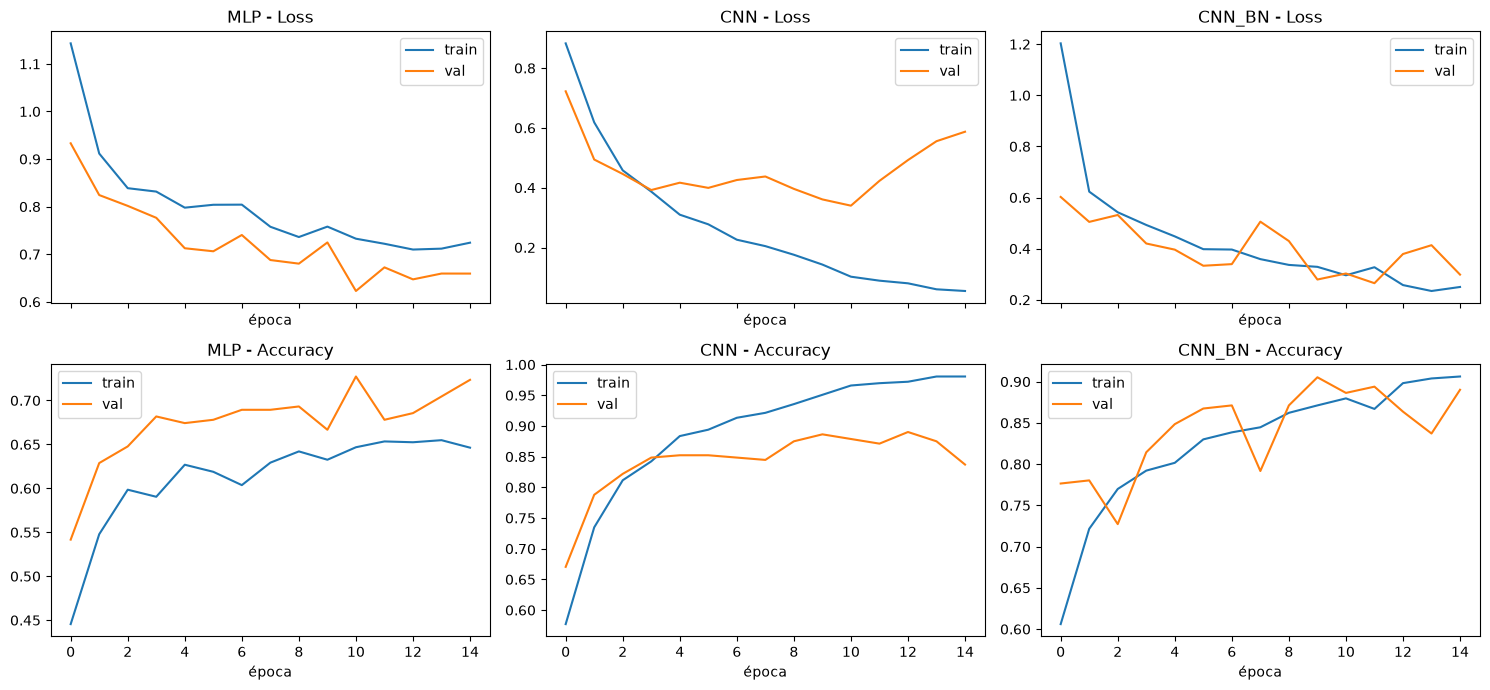

In [27]:
# evolución de loss y accuracy por modelo

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for col, nombre in enumerate(modelos):
    h = historiales[nombre]
    axes[0, col].plot(h['train_loss'], label='train'); axes[0, col].plot(h['val_loss'], label='val')
    axes[0, col].set_title(f'{nombre} - Loss'); axes[0, col].set_xlabel('época'); axes[0, col].legend()

    axes[1, col].plot(h['train_acc'], label='train'); axes[1, col].plot(h['val_acc'], label='val')
    axes[1, col].set_title(f'{nombre} - Accuracy'); axes[1, col].set_xlabel('época'); axes[1, col].legend()
plt.tight_layout(); plt.show()

In [28]:
# evaluación final en el conjunto de test

crit = nn.CrossEntropyLoss()
resultados = []
for nombre, modelo in entrenados.items():
    test_loss, test_acc = run_epoch(modelo, test_loader, crit, None)
    resultados.append((nombre, test_loss, test_acc))

df_resultados = pd.DataFrame(resultados, columns=['Modelo', 'Test Loss', 'Test Accuracy'])
df_resultados

,Modelo,Test Loss,Test Accuracy
0,MLP,0.691715,0.723485
1,CNN,0.415781,0.856061
2,CNN_BN,0.277973,0.912879


### Comparación y discusión de resultados

| Modelo | Test Loss | Test Accuracy |
|---|---|---|
| MLP | 0.69 | 72.3 % |
| CNN | 0.42 | 85.6 % |
| CNN_BN | 0.28 | **91.3 %** |

- **MLP** es el modelo más débil (72.3 % test accuracy, loss 0.69). Al aplanar la imagen pierde toda la estructura espacial (bordes, texturas, formas), por lo que debe aprender a distinguir abeja/mosca/escarabajo a partir de píxeles sueltos — su curva de accuracy de entrenamiento se estanca cerca de 0.65 y nunca se separa mucho de la de validación, señal de que el modelo satura su capacidad antes que de que sobreajuste.
- **CNN** mejora sustancialmente (85.6 %, loss 0.42) gracias a los filtros convolucionales, que sí explotan la estructura espacial y detectan patrones locales (bordes de alas, patas, forma del cuerpo) independientemente de su posición en la imagen. Sin embargo, su train_acc llega a ~0.98 mientras la val_acc se estanca alrededor de 0.85–0.89 y el val_loss empieza a subir después de la época ~10: hay sobreajuste, esperable dado el tamaño moderado del dataset (2112 imágenes de entrenamiento) frente a la capacidad del modelo.
- **CNN_BN**, la arquitectura libre, obtiene el mejor resultado (91.3 %, loss 0.28). La batch normalization estabiliza y acelera el entrenamiento (converge a accuracies altas de validación ya desde las primeras épocas) y el dropout final mitiga el sobreajuste visto en la CNN simple: el gap entre train_acc y val_acc es más pequeño y la val_loss no se dispara como en la CNN sin regularizar.

**Conclusión:** la jerarquía de desempeño (MLP < CNN < CNN_BN) confirma que, para clasificación de imágenes, aprovechar la estructura convolucional es clave frente a un MLP que ignora la geometría de la imagen, y que agregar profundidad junto con regularización (batch norm + dropout) sigue entregando mejoras incluso sin técnicas avanzadas como Transfer Learning.